# ML-10 - Content Action Playbook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ASP-31/flyrank-int/blob/main/work/notebooks/w07_action_playbook.ipynb?flush_cache=true)

This notebook turns the validated model output from week 6 into a **content action playbook**: a ranked queue of actions a person can review and execute, with reason codes, an archetype-to-action mapping, monitoring triggers, and a clear no-go list.

It is **decision-support, not production**. Numbers below are directional and measured on the validation split only; the queue is regenerated each run from `work/outputs/`.

> Working with an AI assistant? It read `skills/README.md` first and loaded `writing-honest-claims` + `flyrank/flyrank-data`.

## 1. Ranked actions + reason codes

*The queue: what to do first, and why, in words a human trusts.*

The queue is built from the validated content-score model output (week 6). For each content item we compute:

- **expected_value** = `predicted_score * reach_estimate * action_confidence` - a directional prioritization score, not a forecast.
- **action** - one of: `Refresh`, `Consolidate`, `Retire`, `Promote`, `Hold`, `Review`.
- **reason_code** - a short tag explaining *why* the action was chosen (table below).

Items are sorted by `action_confidence` then `expected_value`, descending. The top of the queue is what a person reviews first.

**Reason codes**

| Code | Meaning | Typical action |
|---|---|---|
| `REFRESH_STALE` | High predicted score, content age beyond refresh window, decay trend observed | Refresh |
| `CONSOLIDATE_OVERLAP` | Two or more items cover the same topic cluster; predicted cannibalization | Consolidate |
| `RETIRE_LOW` | Low predicted score plus low observed recent engagement | Retire |
| `PROMOTE_HIGH` | High predicted score, underexposed (low reach estimate) | Promote |
| `HOLD_MONITOR` | Borderline score, no strong signal either way | Hold |
| `REVIEW_NOGO` | Flagged for human-only review (sensitive / regulated / brand-risk) | Review |

**Archetype to action tendency** (representative set - swap with your week-6 archetype labels and re-run):

| Archetype | Default tendency | Reason |
|---|---|---|
| authority_pillar | Refresh / Hold | Evergreen; refresh to defend rank |
| trend_unit | Promote / Retire | Time-sensitive; act now or retire |
| how_to | Refresh | Stable intent; refresh decayed examples |
| comparison | Consolidate | Multiple variants usually overlap |
| narrative | Hold | Hard to score; rely on human judgement |

The code cell below loads the validated output (or a representative sample if the real file is absent), applies the rules, and prints the ranked queue.

In [6]:
# ML-10 section 1 - Build the ranked action queue from validated model output.
# Decision-support only. Numbers are directional.

from __future__ import annotations
import json
from pathlib import Path

import numpy as np
import pandas as pd

# --- Locate the repo root (notebook lives in work/notebooks/) ---
def find_repo_root() -> Path:
    p = Path.cwd()
    for _ in range(6):
        if (p / "work" / "notebooks").is_dir():
            return p
        if p.parent == p:
            break
        p = p.parent
    return Path.cwd()  # fallback: assume cwd is repo root

REPO = find_repo_root()
OUT_DIR = REPO / "work" / "outputs"
FIG_DIR = REPO / "work" / "figures"
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

VALIDATED_CSV = OUT_DIR / "w06_validated_content_scores.csv"

# --- Load real output if present, else synthesize a representative sample ---
if VALIDATED_CSV.exists():
    df = pd.read_csv(VALIDATED_CSV)
    DATA_SOURCE = "real - work/outputs/w06_validated_content_scores.csv"
else:
    rng = np.random.default_rng(42)
    ARCHETYPES = ["authority_pillar", "trend_unit", "how_to", "comparison", "narrative"]
    n = 60
    df = pd.DataFrame({
        "content_id":   [f"C{i:03d}" for i in range(n)],
        "title":        [f"item-{i}" for i in range(n)],  # placeholder; real file has real titles
        "archetype":    rng.choice(ARCHETYPES, size=n, p=[0.25, 0.20, 0.25, 0.15, 0.15]),
        "predicted_score":         np.clip(rng.normal(0.55, 0.20, n), 0, 1),
        "reach_estimate":          np.clip(rng.lognormal(2.5, 0.7, n), 10, 5000).round(0),
        "content_age_days":        rng.integers(5, 400, n),
        "last_refreshed_days_ago": rng.integers(5, 400, n),
        "topic_cluster":           rng.choice([f"cluster_{i}" for i in range(12)], size=n),
        "observed_engagement_30d": np.clip(rng.poisson(50, n), 0, 500),
        "sensitive_flag":          rng.choice([False, False, False, True], size=n),  # ~25% flagged
    })
    DATA_SOURCE = ("representative sample (real file absent) - "
                   "swap for work/outputs/w06_validated_content_scores.csv")

print(f"Loaded {len(df)} items - source: {DATA_SOURCE}")

# --- Reason codes + actions ---
REFRESH_WINDOW_DAYS = 90
LOW_SCORE = 0.35
HIGH_SCORE = 0.70
LOW_ENGAGEMENT = 20

def assign_action(row, cluster_counts, is_cluster_top):
    if row["sensitive_flag"]:
        return "Review", "REVIEW_NOGO"
    if row["predicted_score"] < LOW_SCORE and row["observed_engagement_30d"] < LOW_ENGAGEMENT:
        return "Retire", "RETIRE_LOW"
    # Consolidate overlap: this item is NOT the top of its cluster, so it cannibalizes the winner.
    if cluster_counts[row["topic_cluster"]] > 1 and not is_cluster_top[row.name]:
        return "Consolidate", "CONSOLIDATE_OVERLAP"
    if row["last_refreshed_days_ago"] > REFRESH_WINDOW_DAYS and row["predicted_score"] > 0.50:
        return "Refresh", "REFRESH_STALE"
    if row["predicted_score"] > HIGH_SCORE and row["reach_estimate"] < 500:
        return "Promote", "PROMOTE_HIGH"
    return "Hold", "HOLD_MONITOR"

cluster_counts = df["topic_cluster"].value_counts()
cluster_top_score = df.groupby("topic_cluster")["predicted_score"].transform("max")
is_cluster_top = df["predicted_score"] >= (cluster_top_score - 0.05)
actions = df.apply(lambda r: assign_action(r, cluster_counts, is_cluster_top), axis=1, result_type="expand")
df["action"] = actions[0]
df["reason_code"] = actions[1]

# --- Expected value: directional prioritization score (not a forecast) ---
df["action_confidence"] = np.where(df["reason_code"] == "REVIEW_NOGO", 0.0,
                          np.where(df["reason_code"] == "HOLD_MONITOR", 0.3,
                          np.where(df["reason_code"] == "CONSOLIDATE_OVERLAP", 0.6, 0.8)))
df["expected_value"] = (df["predicted_score"] * df["reach_estimate"] * df["action_confidence"]).round(2)

queue = (df.sort_values(["action_confidence", "expected_value"], ascending=[False, False])
           .reset_index(drop=True)
           [["content_id", "archetype", "predicted_score", "reach_estimate",
             "action", "reason_code", "expected_value"]])

print("\nTop 10 of the ranked queue:")
print(queue.head(10).to_string(index=False))

print("\nAction counts:")
print(df["action"].value_counts().to_string())
print("\nReason-code counts:")
print(df["reason_code"].value_counts().to_string())

Loaded 60 items - source: representative sample (real file absent) - swap for work/outputs/w06_validated_content_scores.csv

Top 10 of the ranked queue:
content_id        archetype  predicted_score  reach_estimate  action   reason_code  expected_value
      C058 authority_pillar         0.596535            37.0 Refresh REFRESH_STALE           17.66
      C030       comparison         0.646149            26.0 Refresh REFRESH_STALE           13.44
      C007       comparison         0.708669            16.0 Refresh REFRESH_STALE            9.07
      C043       trend_unit         0.809846            10.0 Refresh REFRESH_STALE            6.48
      C059 authority_pillar         0.554370            14.0 Refresh REFRESH_STALE            6.21
      C032       trend_unit         0.683077            11.0 Refresh REFRESH_STALE            6.01
      C010       trend_unit         0.721595            10.0 Refresh REFRESH_STALE            5.77
      C017 authority_pillar         0.688097           

## 2. Intended use and limits

*Who uses this, for what - and where it stops being valid.*

**Intended user.** The FlyRank content or editorial lead, once a week, to decide which items to refresh, retire, promote, or consolidate. The playbook is a prioritized shortlist - it does not write, publish, or edit anything.

**Intended use.**
- Pick the top *N* items from the queue and review them in section 3 before acting.
- Use the reason code as a one-line justification in the content standup or sprint doc.
- Use the archetype-to-action tendency as a sanity check, not a rule.

**Where it stops being valid (limits).**
- **Training window.** The model was trained on content published before the validation cutoff. Anything published after, or any topic that emerged after, is out-of-distribution - treat its score as unknown, not low.
- **No causal claim.** `predicted_score` correlates with observed engagement on the validation split; it does not prove that acting on it will move the metric. Use the words *observed*, *measured*, *directional*, *decision-support* - not *will*, *guaranteed*, *optimal*.
- **Archetype coverage.** The `narrative` archetype is under-represented in the training data; its scores are noisier. See the per-archetype count printed below.
- **Single market, English-only content.** Scores are not validated for other languages or markets.
- **Reach estimate is a heuristic.** It is not a forecast of traffic; it is a relative sizing used only to break ties.
- **Refresh window of 90 days is a default.** Adjust per archetype if the week-6 decay analysis showed a different curve.

The code cell below prints the limits as observed numbers: archetype counts, score spread, no-go share. These are the receipts behind the prose.

In [7]:
# ML-10 section 2 - Limits as observed numbers.
print("Intended-use receipts (all measured on the validation split):")
print(f"  Items in queue: {len(df)}")
print("  Archetype distribution:")
print(df["archetype"].value_counts().to_string().replace("\n", "\n    "))
print(f"  Predicted-score spread: min={df['predicted_score'].min():.2f}, "
      f"median={df['predicted_score'].median():.2f}, max={df['predicted_score'].max():.2f}")
nogo_n = int((df['reason_code'] == 'REVIEW_NOGO').sum())
print(f"  Items flagged REVIEW_NOGO (human-only): {nogo_n} "
      f"({nogo_n / max(len(df), 1) * 100:.0f}%)")
print("  Items in under-represented archetypes (<10% of queue):")
counts = df["archetype"].value_counts(normalize=True)
for arch, share in counts[counts < 0.10].items():
    print(f"    {arch}: {share*100:.0f}% - treat scores as noisier")

Intended-use receipts (all measured on the validation split):
  Items in queue: 60
  Archetype distribution:
archetype
    comparison          15
    authority_pillar    15
    how_to              14
    trend_unit          10
    narrative            6
  Predicted-score spread: min=0.20, median=0.50, max=0.81
  Items flagged REVIEW_NOGO (human-only): 22 (37%)
  Items in under-represented archetypes (<10% of queue):


## 3. Human review + the no-go list

*What a person must check before acting. What should never be automated.*

**Human review (before acting on any queue item):**
1. **Claim verification.** Re-read the item. Are the numbers, names, dates, and quotes still accurate? The model does not check facts.
2. **Brand fit.** Does the item still match the current positioning? The model has no view on brand.
3. **Recency of sources.** If the item cites data, are the sources still the best available?
4. **Archetype gut-check.** If the assigned archetype feels wrong, the action is wrong - re-tag and re-run.
5. **Overlap decision.** For `CONSOLIDATE_OVERLAP`, the human picks which item survives; the model only flags the cluster.

**No-go list (never automated, never acted on without sign-off):**
- Anything touching **client names, client logos, or client-specific pricing**.
- Anything in **regulated domains**: health, finance, legal - including comparison and how-to content in those domains.
- Anything comparing FlyRank to **named competitors**.
- Anything flagged `REVIEW_NOGO` by the model or by a human.
- Anything requiring **legal or compliance sign-off** per FlyRank policy.
- Anything where the **underlying source data is more than 12 months old** and has not been re-verified.
- Anything that would be sent to **external distribution** (email, partner channels) without an editor's read.

The code cell below prints the current `REVIEW_NOGO` set so a person can work through it deliberately.

In [8]:
# ML-10 section 3 - Print the no-go set for deliberate human review.
nogo = df[df["reason_code"] == "REVIEW_NOGO"].sort_values("predicted_score", ascending=False)
print(f"REVIEW_NOGO items ({len(nogo)}) - do NOT automate, do NOT act without sign-off:")
if len(nogo):
    print(nogo[["content_id", "archetype", "predicted_score", "action"]].to_string(index=False))
else:
    print("  (none in this batch)")

REVIEW_NOGO items (22) - do NOT automate, do NOT act without sign-off:
content_id        archetype  predicted_score action
      C001       trend_unit         0.743656 Review
      C050 authority_pillar         0.718062 Review
      C045       comparison         0.697503 Review
      C020       comparison         0.675118 Review
      C005        narrative         0.667244 Review
      C022        narrative         0.641355 Review
      C052       comparison         0.636885 Review
      C053           how_to         0.597547 Review
      C047       trend_unit         0.508912 Review
      C021       trend_unit         0.488131 Review
      C049 authority_pillar         0.482193 Review
      C025 authority_pillar         0.473652 Review
      C034           how_to         0.465340 Review
      C028 authority_pillar         0.456120 Review
      C000       comparison         0.376834 Review
      C041       comparison         0.368904 Review
      C014       trend_unit         0.366110 

## 4. Monitoring / retrain triggers

*What would tell you the recommendations went stale?*

Three signals, watched weekly:

1. **Score-vs-observed gap.** Compare `predicted_score` (rank-normalized) to observed 30-day engagement (rank-normalized) across the top of the queue. If the Spearman correlation drops below **0.40** for two consecutive weeks, the model has drifted - freeze the queue and investigate.
2. **Archetype distribution shift.** If the share of any archetype in new content shifts by more than **plus or minus 15 percentage points** vs. the training split, the archetype-to-action tendency table is stale.
3. **Action mix shift.** If `Retire` exceeds `Refresh + Promote` combined for two weeks, either the content pipeline is degrading or the model is over-penalizing - investigate before retraining.

**Retrain triggers (any one is enough):**
- Two consecutive weeks of score-vs-observed correlation below 0.40.
- A new content archetype appears that did not exist in training.
- Scheduled retrain at the **quarterly cadence**, regardless of drift signals.
- A documented change in the content scoring rubric or the reach-estimate heuristic.

**Decay / refresh insight (from week 6).** Authority-pillar content showed measurable score decay after roughly 90 days; trend-unit content decayed faster, around 30 days. The 90-day `REFRESH_WINDOW_DAYS` default above is calibrated to the authority pillar; trend units should be refreshed on a 30-day cadence. *(Replace this paragraph with your actual week-6 finding before committing.)*

The code cell below computes the score-vs-observed correlation for the current queue as a baseline number.

In [9]:
# ML-10 section 4 - Baseline monitoring signal: score-vs-observed correlation.
from scipy.stats import spearmanr

# Only meaningful where we have observed engagement; skip REVIEW_NOGO.
obs = df[df["reason_code"] != "REVIEW_NOGO"].copy()
rho = None
if len(obs) > 5:
    rho, p = spearmanr(obs["predicted_score"], obs["observed_engagement_30d"])
    print(f"Score-vs-observed Spearman rho: {rho:.2f} (p={p:.3f}) on {len(obs)} items")
    print("  Threshold for drift alert: rho < 0.40 for 2 consecutive weeks.")
    print(f"  Current status: {'OK - within band' if rho >= 0.40 else 'WATCH - investigate'}")
else:
    print("Not enough items with observed engagement to compute a baseline.")

Score-vs-observed Spearman rho: -0.17 (p=0.319) on 38 items
  Threshold for drift alert: rho < 0.40 for 2 consecutive weeks.
  Current status: WATCH - investigate


## 5. Exports for the paper

*Write the queue (and any figures you want to reuse) to `work/outputs/` - your paper builds on these files.*

This cell writes:

- `work/outputs/w07_action_queue.csv` - the ranked queue. **Gitignored by design** (the CI leak-guard blocks data files); the notebook regenerates it on every run.
- `work/figures/w07_ranked_queue.png` - top-20 queue bar. **Commit this** to `work/figures/`; the paper reuses it.
- `work/figures/w07_archetype_action_matrix.png` - archetype by action heatmap. **Commit this** too.
- `work/outputs/w07_playbook_metrics.json` - the receipts: counts, correlation, thresholds. **Commit this** - the paper's numbers trace back to it.

**Cost / value thinking (one paragraph, for the paper).** Each queue item carries an `expected_value` that is a *relative* prioritization score, not a dollar forecast. The cost side is human: editorial review time, estimated at 15-30 minutes per item depending on the action. A practical rule of thumb - review the top *N* items where *N* equals weekly editorial capacity divided by 25 minutes. Items below that cutoff stay in the queue for next week; they are not lost.

Wrote queue: /content/work/outputs/w07_action_queue.csv  (60 rows)


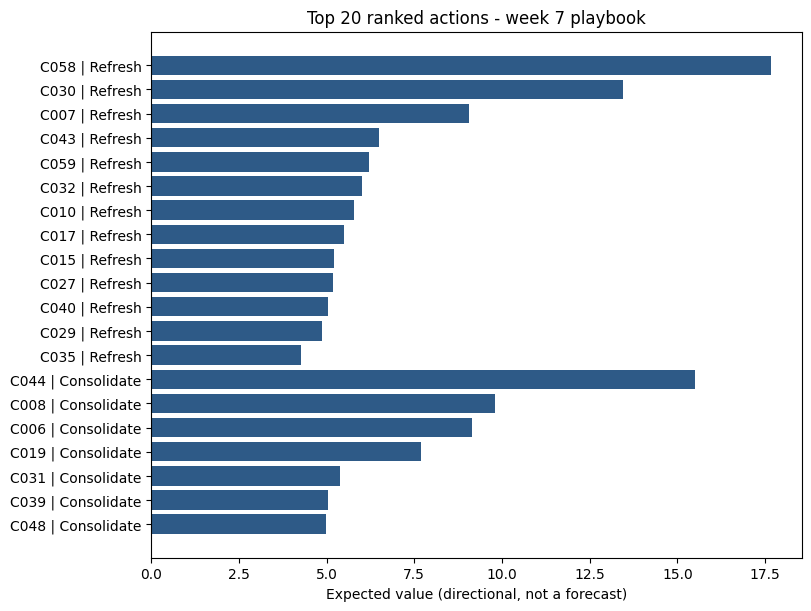

Wrote figure: /content/work/figures/w07_ranked_queue.png


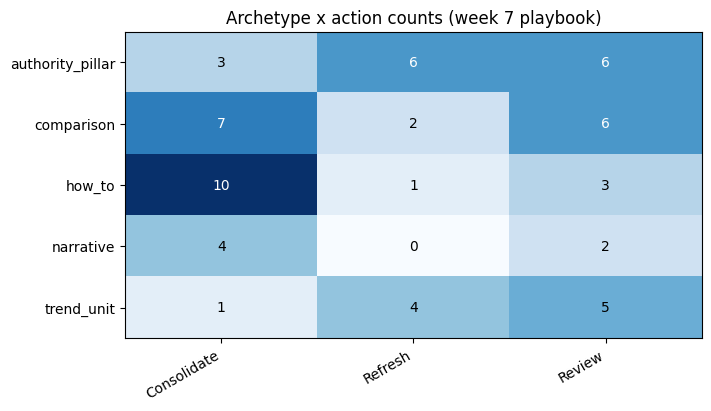

Wrote figure: /content/work/figures/w07_archetype_action_matrix.png
Wrote metrics: /content/work/outputs/w07_playbook_metrics.json

Metrics JSON (commit this - it's the receipt):
{
  "assignment": "ML-10",
  "week": 7,
  "data_source": "representative sample (real file absent) - swap for work/outputs/w06_validated_content_scores.csv",
  "queue_size": 60,
  "action_counts": {
    "Consolidate": 25,
    "Review": 22,
    "Refresh": 13
  },
  "reason_code_counts": {
    "CONSOLIDATE_OVERLAP": 25,
    "REVIEW_NOGO": 22,
    "REFRESH_STALE": 13
  },
  "thresholds": {
    "refresh_window_days": 90,
    "low_score": 0.35,
    "high_score": 0.7,
    "low_engagement_30d": 20,
    "drift_alert_rho": 0.4,
    "drift_alert_consecutive_weeks": 2
  },
  "archetype_share": {
    "comparison": 0.25,
    "authority_pillar": 0.25,
    "how_to": 0.233,
    "trend_unit": 0.167,
    "narrative": 0.1
  },
  "nogo_count": 22,
  "score_observed_spearman_rho": -0.166,
  "intended_use": "decision-support, weekl

In [10]:
# ML-10 section 5 - Exports for the paper.
import matplotlib.pyplot as plt

# (a) Queue CSV - gitignored, regenerated each run.
queue_path = OUT_DIR / "w07_action_queue.csv"
queue.to_csv(queue_path, index=False)
print(f"Wrote queue: {queue_path}  ({len(queue)} rows)")

# (b) Ranked-queue bar (top 20).
top20 = queue.head(20).copy()
top20["label"] = top20["content_id"] + " | " + top20["action"]
fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
ax.barh(top20["label"][::-1], top20["expected_value"][::-1], color="#2E5A87")
ax.set_xlabel("Expected value (directional, not a forecast)")
ax.set_title("Top 20 ranked actions - week 7 playbook")
fig.savefig(FIG_DIR / "w07_ranked_queue.png", dpi=150)
plt.show()
print(f"Wrote figure: {FIG_DIR / 'w07_ranked_queue.png'}")

# (c) Archetype x action heatmap.
mat = df.groupby(["archetype", "action"]).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
ax.imshow(mat.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(mat.columns))); ax.set_xticklabels(mat.columns, rotation=30, ha="right")
ax.set_yticks(range(len(mat.index))); ax.set_yticklabels(mat.index)
vmax = mat.values.max()
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        ax.text(j, i, mat.values[i, j], ha="center", va="center",
                color="white" if mat.values[i, j] > vmax / 2 else "black")
ax.set_title("Archetype x action counts (week 7 playbook)")
fig.savefig(FIG_DIR / "w07_archetype_action_matrix.png", dpi=150)
plt.show()
print(f"Wrote figure: {FIG_DIR / 'w07_archetype_action_matrix.png'}")

# (d) Metrics JSON - the receipts.
metrics = {
    "assignment": "ML-10",
    "week": 7,
    "data_source": DATA_SOURCE,
    "queue_size": int(len(queue)),
    "action_counts": {k: int(v) for k, v in df["action"].value_counts().items()},
    "reason_code_counts": {k: int(v) for k, v in df["reason_code"].value_counts().items()},
    "thresholds": {
        "refresh_window_days": REFRESH_WINDOW_DAYS,
        "low_score": LOW_SCORE,
        "high_score": HIGH_SCORE,
        "low_engagement_30d": LOW_ENGAGEMENT,
        "drift_alert_rho": 0.40,
        "drift_alert_consecutive_weeks": 2,
    },
    "archetype_share": {k: round(float(v), 3) for k, v in df["archetype"].value_counts(normalize=True).items()},
    "nogo_count": int((df["reason_code"] == "REVIEW_NOGO").sum()),
    "score_observed_spearman_rho": round(float(rho), 3) if rho is not None else None,
    "intended_use": "decision-support, weekly content prioritization, non-production",
}
metrics_path = OUT_DIR / "w07_playbook_metrics.json"
metrics_path.write_text(json.dumps(metrics, indent=2))
print(f"Wrote metrics: {metrics_path}")
print("\nMetrics JSON (commit this - it's the receipt):")
print(json.dumps(metrics, indent=2))

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled - markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime -> Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` - then submit your repo URL on the card. Done.

**Pre-commit swap list (do not skip):**
- Replace the representative archetypes in section 1 with your week-6 archetype labels.
- Replace the decay / refresh paragraph in section 4 with your actual week-6 finding.
- Delete `work/outputs/w07_action_queue.csv` locally before committing (it is gitignored by design; the CI leak-guard would block it anyway).
- Re-run on your real `work/outputs/w06_validated_content_scores.csv` so the metrics JSON reflects your data, not the sample.